# COSC 4371 Project. 
# Malware Detection and Cross-Dataset Performance

This notebook inspects BODMAS feature data and metadata to establish
dataset size, label distribution, missing values, duplicates, repeated
entities, and available dates.

Labels: 0 = benign, 1 = malware.

Files: bodmas.npz and bodmas_metadata.csv.

No model training is required for this milestone.


In [1]:
%pip install numpy pandas matplotlib
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 24.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 37.0 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 39.4 MB/s  0:00:00m0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.4
    Uninstalling numpy-2.4.4:
      Successfully uninstalled numpy-2.4.4
  Attempting uninstall: pandas━━━━━━━━━━━━━━━━━━ 0/3 [numpy]
    Found existing installation: pandas 3.0.5 0/3 [numpy]
    Uninstalling pandas-3.0.5:╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [pandas]
      Successfully uninstalled pandas-3.0.5━━━━━━━━━━━━━━━━━━━ 1/3 [pandas]
  Attempting uninstall: matplotlibm━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [pandas]
    Found existing installation: matplotlib 3.11.2━━━━━━━━━━━━ 1/3 [pandas]
   

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score)

RANDOM_STATE = 4371


## B1 - Configure, load, and inspect BODMAS

I will load the BODMAS features and labels from bodmas.npz and the
file information from bodmas_metadata.csv.

X contains the numerical features, and y contains the labels:
0 means benign and 1 means malware.

I will check the sizes and preview the metadata to understand
how the data is organized.

In [3]:
DATA_PATH = Path("bodmas.npz")
METADATA_PATH = Path("bodmas_metadata.csv")

data = np.load(DATA_PATH)
X = data["X"]
y = data["y"]

metadata = pd.read_csv(METADATA_PATH)

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Metadata shape:", metadata.shape)
print("Metadata columns:", metadata.columns.tolist())

display(metadata.head())




Features shape: (134435, 2381)
Labels shape: (134435,)
Metadata shape: (134435, 3)
Metadata columns: ['sha', 'timestamp', 'family']


,sha,timestamp,family
0,e6d7b4bab32def853ab564410df53fa33172dda1bfd48c...,2007-01-01 08:46:39+00:00,NaN
1,5af37a058a5bcf2284c183ee98d92b7c66d8f5ce623e92...,2007-01-26 17:16:30+00:00,NaN
2,5bfbbea150af5cef2d3a93b80ef7c7faea9f564b56045d...,2007-03-21 02:08:53+00:00,NaN
3,216f592f1e1717d5681b7f5f2b14a28a2f0c603b5b7318...,2007-04-25 12:55:06+00:00,NaN
4,a1ca76813d2e9e7e23b830c87fbe29bcb51fcbe096e445...,2007-11-14 15:03:55+00:00,NaN


In [4]:
dates = pd.to_datetime(
    metadata["timestamp"],
    format="mixed",
    errors="coerce",
    utc=True
)

print("Earliest timestamp:", dates.min())
print("Latest timestamp:", dates.max())
print("Missing or invalid timestamps:", dates.isna().sum())

Earliest timestamp: 2007-01-01 08:46:39+00:00
Latest timestamp: 2020-09-30 03:05:27+00:00
Missing or invalid timestamps: 0


In [5]:
print("Timestamp examples:")
print(metadata["timestamp"].head(10))

print("\nExamples that became NaT:")
print(metadata.loc[dates.isna(), "timestamp"].head(10))

Timestamp examples:
0    2007-01-01 08:46:39+00:00
1    2007-01-26 17:16:30+00:00
2    2007-03-21 02:08:53+00:00
3    2007-04-25 12:55:06+00:00
4    2007-11-14 15:03:55+00:00
5    2007-11-27 07:02:34+00:00
6    2008-01-19 23:00:37+00:00
7    2008-03-02 15:46:24+00:00
8    2008-03-22 14:35:47+00:00
9    2008-05-01 00:41:44+00:00
Name: timestamp, dtype: str

Examples that became NaT:
Series([], Name: timestamp, dtype: str)


In [6]:
print("Arrays in bodmas.npz:", data.files)

counts = pd.Series(y).value_counts(dropna=False).sort_index()

print("\nLabel counts:")
print(counts)

print("\nLabel percentages:")
print((counts / len(y) * 100).round(2))

print("\nMissing labels:", pd.isna(y).sum())

Arrays in bodmas.npz: ['X', 'y']

Label counts:
0    77142
1    57293
Name: count, dtype: int64

Label percentages:
0    57.38
1    42.62
Name: count, dtype: float64

Missing labels: 0


In [7]:
print("Rows:", X.shape[0])
print("Feature columns:", X.shape[1])

print("\nMissing feature values (NaN):", np.isnan(X).sum())
print("Infinite feature values:", np.isinf(X).sum())
print("Rows with any invalid feature:",
      (~np.isfinite(X)).any(axis=1).sum())

print("\nMissing hashes:", metadata["sha"].isna().sum())
print("Blank hashes:",
      metadata["sha"].fillna("").str.strip().eq("").sum())

Rows: 134435
Feature columns: 2381

Missing feature values (NaN): 0
Infinite feature values: 0
Rows with any invalid feature: 0

Missing hashes: 0
Blank hashes: 0


In [8]:
hashes = metadata["sha"].str.strip().str.lower()

print("Duplicate hash rows beyond the first:",
      hashes.duplicated().sum())
print("Rows belonging to repeated hashes:",
      hashes.duplicated(keep=False).sum())

families = metadata["family"].fillna("").str.strip()
malware_families = families[(y == 1) & families.ne("")]
family_counts = malware_families.value_counts()

print("\nDistinct malware families:", family_counts.size)
print("Families with more than one sample:",
      family_counts.gt(1).sum())
print("Samples in repeated families:",
      family_counts[family_counts.gt(1)].sum())

print("\nMalware samples without a family:",
      ((y == 1) & families.eq("")).sum())

Duplicate hash rows beyond the first: 0
Rows belonging to repeated hashes: 0

Distinct malware families: 582
Families with more than one sample: 384
Samples in repeated families: 57095

Malware samples without a family: 0


In [9]:
print("Least frequent malware family values:")
print(family_counts.tail(20).to_string())

Least frequent malware family values:
family
lnkwinkap        1
kpot             1
babonock         1
crysis           1
inject           1
pulcare          1
clampi           1
cobalt           1
trickbotcrypt    1
koobface         1
brsecmon         1
shade            1
wannacry         1
pulobe           1
iyeclore         1
stratnil         1
pkprn            1
finfish          1
bfgt             1
kuhaname         1


In [10]:
import hashlib
from collections import Counter

vector_counts = Counter(
    hashlib.sha256(row.tobytes()).digest()
    for row in X
)

print("Duplicate feature rows beyond the first:",
      sum(count - 1 for count in vector_counts.values()))

print("Rows in repeated feature-vector groups:",
      sum(count for count in vector_counts.values() if count > 1))

Duplicate feature rows beyond the first: 7
Rows in repeated feature-vector groups: 14


In [11]:
assert X.shape[0] == len(y) == len(metadata)
assert set(np.unique(y)) == {0, 1}

print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Feature dtype:", X.dtype)
print("Metadata columns:", metadata.columns.tolist())
print("Random seed:", RANDOM_STATE)

Samples: 134435
Features: 2381
Feature dtype: float32
Metadata columns: ['sha', 'timestamp', 'family']
Random seed: 4371


In [12]:
import hashlib

feature_ids = [
    hashlib.sha256(row.tobytes()).hexdigest()
    for row in X
]

bodmas_groups = pd.DataFrame({
    "feature_id": feature_ids,
    "label": y,
    "family": metadata["family"].fillna("").str.strip().to_numpy()
})

label_counts = bodmas_groups.groupby("feature_id")["label"].nunique()

print("Feature-vector groups with conflicting labels:",
      label_counts.gt(1).sum())

print("\nBenign rows with a nonblank family:",
      ((bodmas_groups["label"] == 0)
       & bodmas_groups["family"].ne("")).sum())

Feature-vector groups with conflicting labels: 0

Benign rows with a nonblank family: 0


In [13]:
malware_rows = bodmas_groups[
    bodmas_groups["label"] == 1
]

families_per_vector = (
    malware_rows.groupby("feature_id")["family"].nunique()
)

print("Identical feature groups spanning multiple families:",
      families_per_vector.gt(1).sum())

print("Malware rows with blank families:",
      malware_rows["family"].eq("").sum())

Identical feature groups spanning multiple families: 0
Malware rows with blank families: 0


In [14]:
from sklearn.model_selection import GroupShuffleSplit

groups = np.where(
    y == 1,
    "family:" + bodmas_groups["family"],
    "vector:" + bodmas_groups["feature_id"]
)

indices = np.arange(len(y))

# Reserve 30% of groups for validation and testing.
first_split = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=RANDOM_STATE
)

train_idx, remaining_idx = next(
    first_split.split(indices, y, groups)
)

# Divide the reserved groups between validation and testing.
second_split = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=RANDOM_STATE
)

val_local, test_local = next(
    second_split.split(
        remaining_idx,
        y[remaining_idx],
        groups[remaining_idx]
    )
)

val_idx = remaining_idx[val_local]
test_idx = remaining_idx[test_local]

for name, idx in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx)
]:
    print(
        f"{name}: {len(idx):,} rows "
        f"({len(idx) / len(y):.2%}), "
        f"benign={(y[idx] == 0).sum():,}, "
        f"malware={(y[idx] == 1).sum():,}"
    )

assert not set(groups[train_idx]) & set(groups[val_idx])
assert not set(groups[train_idx]) & set(groups[test_idx])
assert not set(groups[val_idx]) & set(groups[test_idx])

train: 92,844 rows (69.06%), benign=53,997, malware=38,847
validation: 19,114 rows (14.22%), benign=11,572, malware=7,542
test: 22,477 rows (16.72%), benign=11,573, malware=10,904


In [15]:
train_vectors = set(bodmas_groups.iloc[train_idx]["feature_id"])
val_vectors = set(bodmas_groups.iloc[val_idx]["feature_id"])
test_vectors = set(bodmas_groups.iloc[test_idx]["feature_id"])

print("Training rows matching validation features:",
      bodmas_groups.iloc[train_idx]["feature_id"]
      .isin(val_vectors).sum())

print("Training rows matching test features:",
      bodmas_groups.iloc[train_idx]["feature_id"]
      .isin(test_vectors).sum())

print("Validation rows matching test features:",
      bodmas_groups.iloc[val_idx]["feature_id"]
      .isin(test_vectors).sum())

Training rows matching validation features: 0
Training rows matching test features: 0
Validation rows matching test features: 0


In [16]:
print("Arrays available:", data.files)
print("First 10 feature values:")
print(X[0, :10])

print("\nFiles in the BODMAS folder:")
for item in sorted(DATA_PATH.parent.iterdir()):
    if item.is_file():
        print(item.name)

Arrays available: ['X', 'y']
First 10 feature values:
[0.05674198 0.00801749 0.00776239 0.00546647 0.00776239 0.00444606
 0.00543003 0.00306122 0.00947522 0.00630466]

Files in the BODMAS folder:
.DS_Store
GranadosProjectBODMASDataset.ipynb
GranadosProjectEMBER_2018Dataset.ipynb
GranadosProjectUCSB_Dataset.ipynb
Granados_project.ipynb
bodmas.npz
bodmas_malware_category.csv
bodmas_metadata.csv
bodmas_near_pairs_45m.csv
bodmas_near_pairs_5m.csv
bodmas_near_pairs_full.csv
bodmas_scores.csv
bodmas_split.csv
check_checkpoint.py
check_final_checkpoint.py
checkpoint_report.txt
ember_dataset_2018_2.tar.bz2
ember_shared.pkl
requirements.txt
scores.csv
scores.csv.gz
split.csv
split.csv.gz
ucsb_confusion_matrix.png
ucsb_shared.pkl
ucsb_wild_download


In [17]:
# Positions follow the standard EMBER feature ordering.
shared_feature_names = [
    "file_size",
    "size_of_code",
    "size_of_headers",
    "number_of_sections"
]

X_bodmas_shared = pd.DataFrame(
    X[:, [616, 685, 686, 688]],
    columns=shared_feature_names
)

display(X_bodmas_shared.head())

print("Distinct four-feature combinations:",
      X_bodmas_shared.drop_duplicates().shape[0])

,file_size,size_of_code,size_of_headers,number_of_sections
0,27440.0,33792.0,1024.0,3.0
1,1955460.0,2560.0,1024.0,7.0
2,657408.0,1559040.0,1024.0,10.0
3,2967760.0,10752.0,1024.0,4.0
4,3880448.0,514048.0,1024.0,10.0


Distinct four-feature combinations: 103434


In [18]:
shared_keys = pd.MultiIndex.from_frame(X_bodmas_shared)

train_keys = shared_keys[train_idx]
val_keys = shared_keys[val_idx]
test_keys = shared_keys[test_idx]

print("Training rows matching validation inputs:",
      train_keys.isin(val_keys).sum())

print("Training rows matching test inputs:",
      train_keys.isin(test_keys).sum())

print("Validation rows matching test inputs:",
      val_keys.isin(test_keys).sum())

Training rows matching validation inputs: 9692
Training rows matching test inputs: 9803
Validation rows matching test inputs: 2432


In [19]:
# Preserve the original grouped split.
val_idx_original = val_idx.copy()
test_idx_original = test_idx.copy()

# Remove validation inputs already present in training.
val_idx_clean = val_idx_original[
    ~shared_keys[val_idx_original].isin(train_keys)
]

# Remove test inputs present in training or retained validation.
blocked_keys = train_keys.append(shared_keys[val_idx_clean])

test_idx_clean = test_idx_original[
    ~shared_keys[test_idx_original].isin(blocked_keys)
]

print("Validation rows excluded:",
      len(val_idx_original) - len(val_idx_clean))
print("Test rows excluded:",
      len(test_idx_original) - len(test_idx_clean))

for name, idx in [
    ("train", train_idx),
    ("validation", val_idx_clean),
    ("test", test_idx_clean)
]:
    print(
        f"{name}: {len(idx):,} rows, "
        f"benign={(y[idx] == 0).sum():,}, "
        f"malware={(y[idx] == 1).sum():,}"
    )

assert not shared_keys[train_idx].isin(
    shared_keys[val_idx_clean]
).any()
assert not shared_keys[train_idx].isin(
    shared_keys[test_idx_clean]
).any()
assert not shared_keys[val_idx_clean].isin(
    shared_keys[test_idx_clean]
).any()

Validation rows excluded: 4050
Test rows excluded: 3902
train: 92,844 rows, benign=53,997, malware=38,847
validation: 15,064 rows, benign=8,378, malware=6,686
test: 18,575 rows, benign=8,231, malware=10,344


In [20]:
from time import perf_counter
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

start = perf_counter()

baseline.fit(
    X_bodmas_shared.iloc[train_idx],
    y[train_idx]
)

training_seconds = perf_counter() - start

positive_column = list(baseline.classes_).index(1)

validation_scores = baseline.predict_proba(
    X_bodmas_shared.iloc[val_idx_clean]
)[:, positive_column]

print(f"Training time: {training_seconds:.2f} seconds")
print("Validation scores:", len(validation_scores))
print("Distinct validation scores:",
      len(np.unique(validation_scores)))

Training time: 0.14 seconds
Validation scores: 15064
Distinct validation scores: 12914


In [21]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y[val_idx_clean],
    validation_scores,
    drop_intermediate=False
)

eligible = np.flatnonzero(
    (fpr <= 0.05) & np.isfinite(thresholds)
)

if len(eligible):
    # Highest recall; ties favor lower FPR, then higher threshold.
    best = max(
        eligible,
        key=lambda i: (tpr[i], -fpr[i], thresholds[i])
    )
    threshold = float(thresholds[best])
else:
    # Finite threshold above every validation score: predict none positive.
    threshold = float(
        np.nextafter(validation_scores.max(), np.inf)
    )

unrounded_threshold = threshold
threshold = round(unrounded_threshold, 4)

validation_predictions = validation_scores >= threshold
validation_labels = y[val_idx_clean]

print("Chosen threshold:", repr(threshold))
print("Validation false-positive rate:",
      validation_predictions[validation_labels == 0].mean())
print("Validation recall:",
      validation_predictions[validation_labels == 1].mean())


Chosen threshold: 0.6765
Validation false-positive rate: 0.04989257579374552
Validation recall: 0.17439425665569847


In [22]:
bodmas_test_scores = baseline.predict_proba(
    X_bodmas_shared.iloc[test_idx_clean]
)[:, positive_column]

bodmas_row_ids = np.array([
    f"bodmas:{i}" for i in range(len(y))
])

bodmas_split = pd.concat([
    pd.DataFrame({
        "row_id": bodmas_row_ids[idx],
        "dataset": "BODMAS",
        "split": name,
        "label": y[idx]
    })
    for name, idx in [
        ("train", train_idx),
        ("validation", val_idx_clean),
        ("test", test_idx_clean)
    ]
], ignore_index=True)

bodmas_scores = pd.DataFrame({
    "row_id": bodmas_row_ids[test_idx_clean],
    "test_set": "BODMAS held-out",
    "label": y[test_idx_clean],
    "score": bodmas_test_scores
})

print("Split table rows:", len(bodmas_split))
print("Scored test rows:", len(bodmas_scores))
print("Distinct test scores:", bodmas_scores["score"].nunique())

Split table rows: 126483
Scored test rows: 18575
Distinct test scores: 16958


In [23]:
import subprocess
import sys

bodmas_split.to_csv("bodmas_split.csv", index=False)
bodmas_scores.to_csv("bodmas_scores.csv", index=False)

result = subprocess.run(
    [
        sys.executable,
        "check_checkpoint.py",
        "--split", "bodmas_split.csv",
        "--scores", "bodmas_scores.csv",
        "--threshold", repr(threshold)
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

split.csv: 126483 rows. scores.csv: 18575 rows.

Rows per dataset and split
--------------------------
dataset      split  rows  positive  negative  positive %
 BODMAS      train 92844     38847     53997       41.84
 BODMAS validation 15064      6686      8378       44.38
 BODMAS       test 18575     10344      8231       55.69

Metrics per test set (threshold 0.6765; positive when score >= threshold)
-------------------------------------------------------------------------
Each value is followed by its 95% bootstrap interval in brackets.

Test set: BODMAS held-out
  test rows                 18575
  positive rows             10344 (55.69%)
  negative rows             8231 (44.31%)
  bootstrap resamples       1000
  random-scorer AP          0.5569 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.8451 [0.8310, 0.8579]
  recall                    0.2105 [0.2026, 0.2184]
  false-positive rate       0.0485 [0.0442, 0.0529]
  AP                 

In [24]:
ember_shared = pd.read_pickle("ember_shared.pkl")

assert ember_shared["row_id"].is_unique
assert ember_shared["label"].isin([0, 1]).all()

print("Loaded EMBER records:", len(ember_shared))
print("Shared features:", shared_feature_names)

Loaded EMBER records: 800000
Shared features: ['file_size', 'size_of_code', 'size_of_headers', 'number_of_sections']


In [25]:
# Normalize file hashes for comparison.
bodmas_hashes = (
    metadata["sha"].astype(str).str.strip().str.lower()
)
ember_hashes = (
    ember_shared["sha256"].astype(str).str.strip().str.lower()
)

# Protect both model fitting and threshold selection.
development_idx = np.concatenate([train_idx, val_idx_clean])

development_hashes = set(bodmas_hashes.iloc[development_idx])
development_keys = pd.MultiIndex.from_frame(
    X_bodmas_shared.iloc[development_idx]
)

ember_keys = pd.MultiIndex.from_frame(
    ember_shared[shared_feature_names]
)

ember_hash_overlap = ember_hashes.isin(development_hashes)
ember_feature_overlap = ember_keys.isin(development_keys)

ember_exclude = (
    ember_hash_overlap.to_numpy() | ember_feature_overlap
)

print("EMBER rows matching BODMAS train/validation hashes:",
      ember_hash_overlap.sum())
print("EMBER rows matching BODMAS train/validation inputs:",
      ember_feature_overlap.sum())
print("Total EMBER rows to exclude:", ember_exclude.sum())
print("EMBER rows remaining:", (~ember_exclude).sum())

EMBER rows matching BODMAS train/validation hashes: 27
EMBER rows matching BODMAS train/validation inputs: 113118
Total EMBER rows to exclude: 113118
EMBER rows remaining: 686882


In [26]:
ember_test = ember_shared.loc[~ember_exclude].copy()

# Confirm no overlap with BODMAS training or validation.
assert not (
    ember_test["sha256"].astype(str).str.strip().str.lower()
    .isin(development_hashes).any()
)

assert not pd.MultiIndex.from_frame(
    ember_test[shared_feature_names]
).isin(development_keys).any()

print("EMBER external test rows:", len(ember_test))
print("\nClass counts:")
print(ember_test["label"].value_counts().sort_index())

# Score once using the existing model; do not retrain.
ember_test_scores = baseline.predict_proba(
    ember_test[shared_feature_names]
)[:, positive_column]

ember_scores = pd.DataFrame({
    "row_id": ember_test["row_id"].to_numpy(),
    "test_set": "EMBER external",
    "label": ember_test["label"].to_numpy(),
    "score": ember_test_scores
})

print("\nScored rows:", len(ember_scores))
print("Distinct scores:", ember_scores["score"].nunique())

EMBER external test rows: 686882

Class counts:
label
0    333268
1    353614
Name: count, dtype: int64

Scored rows: 686882
Distinct scores: 412458


In [27]:
ember_split = pd.DataFrame({
    "row_id": ember_test["row_id"].to_numpy(),
    "dataset": "EMBER 2018",
    "split": "test",
    "label": ember_test["label"].to_numpy()
})

checkpoint_split = pd.concat(
    [bodmas_split, ember_split], ignore_index=True
)

checkpoint_scores = pd.concat(
    [bodmas_scores, ember_scores], ignore_index=True
)

checkpoint_split.to_csv("split.csv", index=False)
checkpoint_scores.to_csv("scores.csv", index=False)

result = subprocess.run(
    [
        sys.executable,
        "check_checkpoint.py",
        "--split", "split.csv",
        "--scores", "scores.csv",
        "--threshold", repr(threshold)
    ],
    capture_output=True,
    text=True
)

# Save the full report in case notebook output is truncated.
Path("checkpoint_report.txt").write_text(
    result.stdout + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

split.csv: 813365 rows. scores.csv: 705457 rows.

Rows per dataset and split
--------------------------
   dataset      split   rows  positive  negative  positive %
    BODMAS      train  92844     38847     53997       41.84
    BODMAS validation  15064      6686      8378       44.38
    BODMAS       test  18575     10344      8231       55.69
EMBER 2018       test 686882    353614    333268       51.48

Metrics per test set (threshold 0.6765; positive when score >= threshold)
-------------------------------------------------------------------------
Each value is followed by its 95% bootstrap interval in brackets.

Test set: BODMAS held-out
  test rows                 18575
  positive rows             10344 (55.69%)
  negative rows             8231 (44.31%)
  bootstrap resamples       1000
  random-scorer AP          0.5569 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.8451 [0.8310, 0.8579]
  recall                    0.2105 [0.2026, 0.2

In [28]:
report = Path("checkpoint_report.txt").read_text(encoding="utf-8")

ember_section = report.split("Test set: EMBER external", 1)[1]
print("Test set: EMBER external" + ember_section)

Test set: EMBER external
  test rows                 686882
  positive rows             353614 (51.48%)
  negative rows             333268 (48.52%)
  bootstrap resamples       200
  random-scorer AP          0.5148 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.6029 [0.6001, 0.6061]
  recall                    0.1725 [0.1713, 0.1737]
  false-positive rate       0.1206 [0.1195, 0.1217]
  AP                        0.6113 [0.6096, 0.6131]
  AUROC                     0.6337 [0.6325, 0.6350]

Warnings
--------
None.



In [29]:
ucsb_shared = pd.read_pickle("ucsb_shared.pkl")

print("Loaded UCSB rows:", len(ucsb_shared))
print("Shared features:", shared_feature_names)

Loaded UCSB rows: 50724
Shared features: ['file_size', 'size_of_code', 'size_of_headers', 'number_of_sections']


In [30]:
ucsb_keys = pd.MultiIndex.from_frame(
    ucsb_shared[shared_feature_names]
)

ucsb_exclude = ucsb_keys.isin(development_keys)

print("UCSB rows matching BODMAS train/validation inputs:",
      ucsb_exclude.sum())
print("UCSB rows remaining:", (~ucsb_exclude).sum())

print("\nRemaining class counts:")
print(
    ucsb_shared.loc[~ucsb_exclude, "label"]
    .value_counts()
    .sort_index()
)

UCSB rows matching BODMAS train/validation inputs: 5876
UCSB rows remaining: 44848

Remaining class counts:
label
0    16183
1    28665
Name: count, dtype: int64


In [31]:
ucsb_test = ucsb_shared.loc[~ucsb_exclude].copy()

assert not pd.MultiIndex.from_frame(
    ucsb_test[shared_feature_names]
).isin(development_keys).any()

ucsb_test_scores = baseline.predict_proba(
    ucsb_test[shared_feature_names]
)[:, positive_column]

ucsb_scores = pd.DataFrame({
    "row_id": ucsb_test["row_id"].to_numpy(),
    "test_set": "UCSB Wild external",
    "label": ucsb_test["label"].to_numpy(),
    "score": ucsb_test_scores
})

ucsb_split = pd.DataFrame({
    "row_id": ucsb_test["row_id"].to_numpy(),
    "dataset": "UCSB Wild",
    "split": "test",
    "label": ucsb_test["label"].to_numpy()
})

print("Scored UCSB rows:", len(ucsb_scores))
print("Distinct scores:", ucsb_scores["score"].nunique())

Scored UCSB rows: 44848
Distinct scores: 30355


In [32]:
checkpoint_split = pd.concat(
    [bodmas_split, ember_split, ucsb_split],
    ignore_index=True
)

checkpoint_scores = pd.concat(
    [bodmas_scores, ember_scores, ucsb_scores],
    ignore_index=True
)

assert checkpoint_split["row_id"].is_unique

checkpoint_split.to_csv("split.csv", index=False)
checkpoint_scores.to_csv("scores.csv", index=False)

result = subprocess.run(
    [
        sys.executable,
        "check_checkpoint.py",
        "--split", "split.csv",
        "--scores", "scores.csv",
        "--threshold", repr(threshold)
    ],
    capture_output=True,
    text=True
)

report = result.stdout + result.stderr
Path("checkpoint_report.txt").write_text(report, encoding="utf-8")

if result.returncode != 0:
    print(report)
else:
    print(report.split("Metrics per test set", 1)[0])
    print("Test set: UCSB Wild external")
    print(report.split("Test set: UCSB Wild external", 1)[1])

split.csv: 858213 rows. scores.csv: 750305 rows.

Rows per dataset and split
--------------------------
   dataset      split   rows  positive  negative  positive %
    BODMAS      train  92844     38847     53997       41.84
    BODMAS validation  15064      6686      8378       44.38
    BODMAS       test  18575     10344      8231       55.69
EMBER 2018       test 686882    353614    333268       51.48
 UCSB Wild       test  44848     28665     16183       63.92


Test set: UCSB Wild external

  test rows                 44848
  positive rows             28665 (63.92%)
  negative rows             16183 (36.08%)
  bootstrap resamples       1000
  random-scorer AP          0.6392 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.8264 [0.8196, 0.8333]
  recall                    0.3039 [0.2986, 0.3091]
  false-positive rate       0.1131 [0.1083, 0.1179]
  AP                        0.7731 [0.7675, 0.7782]
  AUROC                     0.6387 [0.6

In [33]:
from scipy.spatial.distance import pdist

NEAR_SAMPLE_SIZE = 1000
rng = np.random.default_rng(RANDOM_STATE)

near_sample_idx = np.sort(
    rng.choice(len(X), size=NEAR_SAMPLE_SIZE, replace=False)
)

# Hamming distance = proportion of feature positions that differ.
distances = pdist(X[near_sample_idx], metric="hamming")

pair_i, pair_j = np.triu_indices(NEAR_SAMPLE_SIZE, k=1)

near_mask = (distances > 0) & (distances <= 0.01)

near_pairs = pd.DataFrame({
    "row_a": near_sample_idx[pair_i[near_mask]],
    "row_b": near_sample_idx[pair_j[near_mask]],
    "different_feature_fraction": distances[near_mask]
})

print("Rows sampled:", NEAR_SAMPLE_SIZE)
print("Seed:", RANDOM_STATE)
print("Exact feature-vector pairs in sample:",
      (distances == 0).sum())
print("Candidate near-duplicate pairs:", len(near_pairs))

involved_rows = set(near_pairs["row_a"]) | set(near_pairs["row_b"])
print("Sample rows involved:", len(involved_rows))

Rows sampled: 1000
Seed: 4371
Exact feature-vector pairs in sample: 0
Candidate near-duplicate pairs: 1
Sample rows involved: 2


In [34]:
split_lookup = pd.Series("excluded", index=np.arange(len(y)))
split_lookup.loc[train_idx] = "train"
split_lookup.loc[val_idx_clean] = "validation"
split_lookup.loc[test_idx_clean] = "test"

near_pairs["split_a"] = near_pairs["row_a"].map(split_lookup)
near_pairs["split_b"] = near_pairs["row_b"].map(split_lookup)

near_pairs["crosses_retained_boundary"] = (
    near_pairs["split_a"].ne("excluded")
    & near_pairs["split_b"].ne("excluded")
    & near_pairs["split_a"].ne(near_pairs["split_b"])
)

display(near_pairs)

print("Candidate pairs crossing retained split boundaries:",
      near_pairs["crosses_retained_boundary"].sum())

,row_a,row_b,different_feature_fraction,split_a,split_b,crosses_retained_boundary
0,26049,99322,0.0042,test,test,False


Candidate pairs crossing retained split boundaries: 0


In [35]:
from time import perf_counter
from scipy.spatial.distance import pdist

rng = np.random.default_rng(RANDOM_STATE)
timing_idx = rng.choice(len(X), size=2000, replace=False)

start = perf_counter()
timing_distances = pdist(X[timing_idx], metric="hamming")
elapsed = perf_counter() - start

sample_pairs = 2000 * 1999 // 2
full_pairs = len(X) * (len(X) - 1) // 2

estimated_hours = (
    elapsed * full_pairs / sample_pairs / 3600
)

print(f"Timing check: {elapsed:.2f} seconds")
print(f"Full dataset pairs: {full_pairs:,}")
print(f"Estimated full-check time: {estimated_hours:.2f} hours")

del timing_distances

Timing check: 2.61 seconds
Full dataset pairs: 9,036,317,395
Estimated full-check time: 3.28 hours


In [36]:
from time import perf_counter

PAIR_SAMPLE_SIZE = 45_000_000
PAIR_BATCH_SIZE = 1000
rng = np.random.default_rng(RANDOM_STATE)

n = len(X)
total_pairs = n * (n - 1) // 2

# Sample distinct unordered pairs uniformly, without self-pairs.
pair_ids = rng.choice(
    total_pairs, size=PAIR_SAMPLE_SIZE, replace=False
)

# Map each pair ID to its two row positions.
row_starts = (
    np.arange(n, dtype=np.int64) * n
    - np.arange(n, dtype=np.int64)
    * (np.arange(n, dtype=np.int64) + 1) // 2
)

split_names = np.full(n, "excluded", dtype=object)
split_names[train_idx] = "train"
split_names[val_idx_clean] = "validation"
split_names[test_idx_clean] = "test"

exact_pairs = 0
near_parts = []
start = perf_counter()

for offset in range(0, PAIR_SAMPLE_SIZE, PAIR_BATCH_SIZE):
    ids = pair_ids[offset:offset + PAIR_BATCH_SIZE]

    rows_a = np.searchsorted(row_starts, ids, side="right") - 1
    rows_b = rows_a + 1 + (ids - row_starts[rows_a])

    differences = np.count_nonzero(
        X[rows_a] != X[rows_b], axis=1
    )

    exact_pairs += int((differences == 0).sum())
    near = (differences > 0) & (differences <= int(0.01 * X.shape[1]))

    if near.any():
        near_parts.append(pd.DataFrame({
            "row_a": rows_a[near],
            "row_b": rows_b[near],
            "different_features": differences[near]
        }))

    if (offset + PAIR_BATCH_SIZE) % 500_000 == 0:
        print("Pairs checked:", offset + PAIR_BATCH_SIZE, flush=True)

near_pairs_5m = (
    pd.concat(near_parts, ignore_index=True)
    if near_parts else
    pd.DataFrame(columns=["row_a", "row_b", "different_features"])
)

near_pairs_5m["split_a"] = [
    split_names[int(i)] for i in near_pairs_5m["row_a"]
]
near_pairs_5m["split_b"] = [
    split_names[int(i)] for i in near_pairs_5m["row_b"]
]

crossing = (
    near_pairs_5m["split_a"].ne("excluded")
    & near_pairs_5m["split_b"].ne("excluded")
    & near_pairs_5m["split_a"].ne(near_pairs_5m["split_b"])
)

near_pairs_5m.to_csv("bodmas_near_pairs_45m.csv", index=False)

print("\nPairs sampled:", PAIR_SAMPLE_SIZE)
print("Seed:", RANDOM_STATE)
print("Exact pairs sampled:", exact_pairs)
print("Candidate near-duplicate pairs:", len(near_pairs_5m))
print("Pairs crossing retained boundaries:", crossing.sum())
print(f"Elapsed minutes: {(perf_counter() - start) / 60:.2f}")

Pairs checked: 500000
Pairs checked: 1000000
Pairs checked: 1500000
Pairs checked: 2000000
Pairs checked: 2500000
Pairs checked: 3000000
Pairs checked: 3500000
Pairs checked: 4000000
Pairs checked: 4500000
Pairs checked: 5000000
Pairs checked: 5500000
Pairs checked: 6000000
Pairs checked: 6500000
Pairs checked: 7000000
Pairs checked: 7500000
Pairs checked: 8000000
Pairs checked: 8500000
Pairs checked: 9000000
Pairs checked: 9500000
Pairs checked: 10000000
Pairs checked: 10500000
Pairs checked: 11000000
Pairs checked: 11500000
Pairs checked: 12000000
Pairs checked: 12500000
Pairs checked: 13000000
Pairs checked: 13500000
Pairs checked: 14000000
Pairs checked: 14500000
Pairs checked: 15000000
Pairs checked: 15500000
Pairs checked: 16000000
Pairs checked: 16500000
Pairs checked: 17000000
Pairs checked: 17500000
Pairs checked: 18000000
Pairs checked: 18500000
Pairs checked: 19000000
Pairs checked: 19500000
Pairs checked: 20000000
Pairs checked: 20500000
Pairs checked: 21000000
Pairs checke

In [37]:
print("Pairs sampled:", len(pair_ids))
print("Distinct rows represented:",
      len(set(near_pairs_5m["row_a"]) | set(near_pairs_5m["row_b"])))

Pairs sampled: 45000000
Distinct rows represented: 122


In [38]:
training_inputs = pd.MultiIndex.from_frame(
    X_bodmas_shared.iloc[train_idx]
)

validation_inputs = pd.MultiIndex.from_frame(
    X_bodmas_shared.iloc[val_idx_clean]
)

all_test_inputs = pd.MultiIndex.from_frame(
    pd.concat([
        X_bodmas_shared.iloc[test_idx_clean],
        ember_test[shared_feature_names],
        ucsb_test[shared_feature_names]
    ], ignore_index=True)
)

train_test_matches = training_inputs.isin(all_test_inputs).sum()
train_validation_matches = training_inputs.isin(validation_inputs).sum()

print("Training rows matching any test set:", train_test_matches)
print("Training rows matching validation:", train_validation_matches)

assert train_test_matches == 0
assert train_validation_matches == 0

Training rows matching any test set: 0
Training rows matching validation: 0


In [39]:
import sys
from importlib.metadata import version
from pathlib import Path

packages = [
    "numpy", "pandas", "scipy",
    "scikit-learn", "matplotlib"
]

print("Python:", sys.version.split()[0])

requirements = [
    f"{package}=={version(package)}"
    for package in packages
]

print("\n".join(requirements))

Path("requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

Python: 3.14.3
numpy==2.4.2
pandas==3.0.6
scipy==1.17.1
scikit-learn==1.8.0
matplotlib==3.10.8


80

In [40]:
threshold = 0.6765

result = subprocess.run(
    [
        sys.executable,
        "check_checkpoint.py",
        "--split", "split.csv",
        "--scores", "scores.csv",
        "--threshold", str(threshold)
    ],
    capture_output=True,
    text=True
)

report = result.stdout + result.stderr
Path("checkpoint_report.txt").write_text(report, encoding="utf-8")
print(report)

split.csv: 858213 rows. scores.csv: 750305 rows.

Rows per dataset and split
--------------------------
   dataset      split   rows  positive  negative  positive %
    BODMAS      train  92844     38847     53997       41.84
    BODMAS validation  15064      6686      8378       44.38
    BODMAS       test  18575     10344      8231       55.69
EMBER 2018       test 686882    353614    333268       51.48
 UCSB Wild       test  44848     28665     16183       63.92

Metrics per test set (threshold 0.6765; positive when score >= threshold)
-------------------------------------------------------------------------
Each value is followed by its 95% bootstrap interval in brackets.

Test set: BODMAS held-out
  test rows                 18575
  positive rows             10344 (55.69%)
  negative rows             8231 (44.31%)
  bootstrap resamples       1000
  random-scorer AP          0.5569 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.8451 [0.

In [41]:
report = Path("checkpoint_report.txt").read_text(encoding="utf-8")

for line in report.splitlines():
    text = line.strip()
    if text.startswith((
        "Test set:", "precision ", "recall ",
        "false-positive rate ", "AP ", "AUROC "
    )):
        print(text)

Test set: BODMAS held-out
precision                 0.8451 [0.8310, 0.8579]
recall                    0.2105 [0.2026, 0.2184]
false-positive rate       0.0485 [0.0442, 0.0529]
AP                        0.6902 [0.6811, 0.6993]
AUROC                     0.6103 [0.6022, 0.6184]
Test set: EMBER external
precision                 0.6029 [0.6001, 0.6061]
recall                    0.1725 [0.1713, 0.1737]
false-positive rate       0.1206 [0.1195, 0.1217]
AP                        0.6113 [0.6096, 0.6131]
AUROC                     0.6337 [0.6325, 0.6350]
Test set: UCSB Wild external
precision                 0.8264 [0.8196, 0.8333]
recall                    0.3039 [0.2986, 0.3091]
false-positive rate       0.1131 [0.1083, 0.1179]
AP                        0.7731 [0.7675, 0.7782]
AUROC                     0.6387 [0.6336, 0.6431]


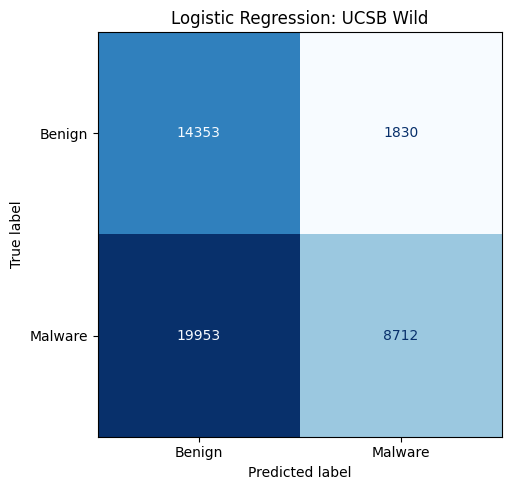

Confusion matrix:
[[14353  1830]
 [19953  8712]]


In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

threshold = 0.6765

y_true = ucsb_scores["label"].to_numpy()
y_pred = (
    ucsb_scores["score"].to_numpy() >= threshold
).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malware"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Logistic Regression: UCSB Wild")
fig.tight_layout()
fig.savefig("ucsb_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix:")
print(cm)

In [43]:
import gzip
import shutil
from pathlib import Path

for name in ["split.csv", "scores.csv"]:
    source = Path(name)
    destination = Path(name + ".gz")

    with source.open("rb") as original:
        with gzip.open(destination, "wb") as compressed:
            shutil.copyfileobj(original, compressed)

    print(f"{destination.name}: {destination.stat().st_size / 1_000_000:.2f} MB")
    

split.csv.gz: 2.38 MB
scores.csv.gz: 8.91 MB


In [44]:
import random

cutoff = 0.6765

false_positives = bodmas_scores.loc[
    (bodmas_scores["label"] == 0) & (bodmas_scores["score"] >= cutoff),
    "row_id",
]

false_negatives = bodmas_scores.loc[
    (bodmas_scores["label"] == 1) & (bodmas_scores["score"] < cutoff),
    "row_id",
]

rng = random.Random(4371)
sampled_fp = rng.sample(sorted(false_positives), min(10, len(false_positives)))
sampled_fn = rng.sample(sorted(false_negatives), min(10, len(false_negatives)))

print(f"Total errors: {len(false_positives)} FP, {len(false_negatives)} FN")
print(f"Sampled false positives ({len(sampled_fp)}):", sampled_fp)
print(f"Sampled false negatives ({len(sampled_fn)}):", sampled_fn)

Total errors: 399 FP, 8167 FN
Sampled false positives (10): ['bodmas:65125', 'bodmas:47584', 'bodmas:3755', 'bodmas:81633', 'bodmas:22224', 'bodmas:13711', 'bodmas:23570', 'bodmas:64354', 'bodmas:111266', 'bodmas:65071']
Sampled false negatives (10): ['bodmas:19292', 'bodmas:35584', 'bodmas:67766', 'bodmas:54118', 'bodmas:124404', 'bodmas:28556', 'bodmas:70338', 'bodmas:77503', 'bodmas:69556', 'bodmas:29796']


In [46]:
from pathlib import Path

final_scores = checkpoint_scores.rename(columns={"test_set": "value"}).assign(
    column="Logistic regression",
    threshold=0.6765,
)

score_columns = ["row_id", "value", "column", "label", "score", "threshold"]
final_scores[score_columns].to_csv("scores.csv", index=False)
checkpoint_split.to_csv("split.csv", index=False)

from pathlib import Path

print("Saved to:", Path.cwd())
print(f"scores.csv: {len(final_scores):,} rows")
print(f"split.csv: {len(checkpoint_split):,} rows")
print("Score columns:", final_scores[score_columns].columns.tolist())

Saved to: /Users/roman/Desktop/4371 project/project code
scores.csv: 750,305 rows
split.csv: 858,213 rows
Score columns: ['row_id', 'value', 'column', 'label', 'score', 'threshold']


In [47]:
import gzip

final_scores[score_columns].to_csv(
    "scores.csv.gz", index=False, compression="gzip"
)

with gzip.open("scores.csv.gz", "rt") as file:
    print(file.readline().strip())

row_id,value,column,label,score,threshold


In [48]:
from time import perf_counter

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

models = {
    "Random forest": RandomForestClassifier(random_state=4371, n_jobs=-1),
    "Gradient boosting": GradientBoostingClassifier(random_state=4371),
}

test_sets = [
    (X_bodmas_shared.iloc[test_idx_clean], bodmas_scores),
    (ember_test[shared_feature_names], ember_scores),
    (ucsb_test[shared_feature_names], ucsb_scores),
]

validation_features = X_bodmas_shared.iloc[val_idx_clean]
validation_labels = y[val_idx_clean]
new_scores = []

for name, model in models.items():
    start = perf_counter()
    model.fit(X_bodmas_shared.iloc[train_idx], y[train_idx])
    training_seconds = perf_counter() - start

    positive_index = list(model.classes_).index(1)
    val_scores = model.predict_proba(validation_features)[:, positive_index]
    fpr, recall, cutoffs = roc_curve(
        validation_labels, val_scores, drop_intermediate=False
    )
    eligible = np.flatnonzero((fpr <= 0.05) & np.isfinite(cutoffs))
    if len(eligible):
        best = max(eligible, key=lambda i: (recall[i], -fpr[i], cutoffs[i]))
        cutoff = float(cutoffs[best])
    else:
        cutoff = float(np.nextafter(val_scores.max(), np.inf))

    print(f"\n{name}: {training_seconds:.2f} seconds to train")
    print(f"Validation threshold: {cutoff:.8g}")

    for features, saved_scores in test_sets:
        scores = model.predict_proba(features)[:, positive_index]
        rows = saved_scores.rename(columns={"test_set": "value"}).assign(
            column=name, score=scores, threshold=cutoff
        )
        new_scores.append(rows[score_columns])
        print(f"{rows['value'].iloc[0]}: AUROC {roc_auc_score(rows['label'], scores):.4f}")

all_scores = pd.concat([final_scores[score_columns], *new_scores], ignore_index=True)
all_scores.to_csv("scores_all_models.csv.gz", index=False, compression="gzip")
print(f"\nSaved {len(all_scores):,} rows to scores_all_models.csv.gz")


Random forest: 1.22 seconds to train
Validation threshold: 0.27333333
BODMAS held-out: AUROC 0.9271
EMBER external: AUROC 0.7324
UCSB Wild external: AUROC 0.7936

Gradient boosting: 4.52 seconds to train
Validation threshold: 0.58766476
BODMAS held-out: AUROC 0.8536
EMBER external: AUROC 0.6801
UCSB Wild external: AUROC 0.6528

Saved 2,250,915 rows to scores_all_models.csv.gz
